# Setup

In [1]:
import os
import json 
import numpy as np
from util import *
import matplotlib.pyplot as plt
%matplotlib ipympl

In [3]:
# load preprocessed keypoints
recording_name = 'p2'
filename_keypoints = os.path.join('data', recording_name, recording_name+'_keypoints_3d_global.npy')
filename_metadata = os.path.join('data', recording_name, recording_name+'_metadata.json')
if not os.path.exists(filename_keypoints):
    raise FileNotFoundError(f'File {filename_keypoints} does not exist')
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f'File {filename_metadata} does not exits')
keypoints = np.load(filename_keypoints)
with open(filename_metadata) as f:
    metadata = json.load(f)
print(f'loaded: {filename_keypoints} \nshape: {keypoints.shape}')

loaded: data\p2\p2_keypoints_3d_global.npy 
shape: (3566, 26, 3)


In [4]:
for i, label in enumerate(stereo_labels):
    print(i, label)

0 nose
1 left_eye
2 right_eye
3 left_ear
4 right_ear
5 left_shoulder
6 right_shoulder
7 left_elbow
8 right_elbow
9 left_wrist
10 right_wrist
11 left_hip
12 right_hip
13 left_knee
14 right_knee
15 left_ankle
16 right_ankle
17 top_head
18 neck
19 mid_hip
20 left_big_toe
21 right_big_toe
22 left_small_toe
23 right_small_toe
24 left_heel
25 right_heel
26 mid_shoulder


# Draw trajectories

In [ ]:
KPT_IDX = 18
cut = 300
PLOT_ORIGINAL = True

horizontal = keypoints[cut:,KPT_IDX,0]
vertical = keypoints[cut:,KPT_IDX,1]
depth = keypoints[cut:,KPT_IDX,2]

# horizontal_acceleration = np.diff(horizontal, n=1, prepend=horizontal[:2])
# vertical_acceleration = np.diff(vertical, n=1, prepend=vertical[:2])
# depth_acceleration = np.diff(depth, n=1, prepend=depth[:2])

# horizontal_acceleration = np.gradient(np.gradient(horizontal))
# vertical_acceleration = np.gradient(np.gradient(vertical))
# depth_acceleration = np.gradient(np.gradient(depth))
horizontal_acceleration = np.gradient(horizontal)
vertical_acceleration = np.gradient(vertical)
depth_acceleration = np.gradient(depth)



plt.close('all')
fig, axs = plt.subplots(3,1, figsize=(15,5))
fig.suptitle(f'keypoint {KPT_IDX}')

axs[0].set_title('horizontal')
axs[0].plot(horizontal_acceleration)

axs[1].set_title('vertical')
axs[1].plot(vertical_acceleration)

axs[2].set_title('depth')
axs[2].plot(depth_acceleration)
# axs[2].hlines(y=[depth_std+np.nanmean(depth), np.nanmean(depth)-depth_std], xmin=0, xmax=len(depth), color='r')


for ax in axs[:-1]:
    ax.set_xticks([])
    # ax.grid()
plt.tight_layout()


if PLOT_ORIGINAL:
    fig, axs = plt.subplots(3,1, figsize=(15,5))
    fig.suptitle(f'ORIGINAL')

    axs[0].set_title('horizontal')
    axs[0].plot(horizontal)

    axs[1].set_title('vertical')
    axs[1].plot(vertical)

    axs[2].set_title('depth')
    axs[2].plot(depth)


    for ax in axs[:-1]:
        ax.set_xticks([])
        # ax.grid()
    plt.tight_layout()

In [23]:
position = keypoints[cut:, KPT_IDX, :]  # meters

velocity = np.gradient(position, delta_t, axis=0)  # vector, m/s
velocity_magnitude = np.linalg.norm(velocity, axis=1)  # vector magnitude

acceleration_magnitude = np.gradient(velocity_magnitude, delta_t, axis=0)  # vector, m/s^2
# acceleration_magnitude = np.linalg.norm(acceleration, axis=1)  # vector magnitude

print(velocity.shape)
print(velocity_magnitude.shape)
print(acceleration_magnitude.shape)

(3266, 3)
(3266,)
(3266,)


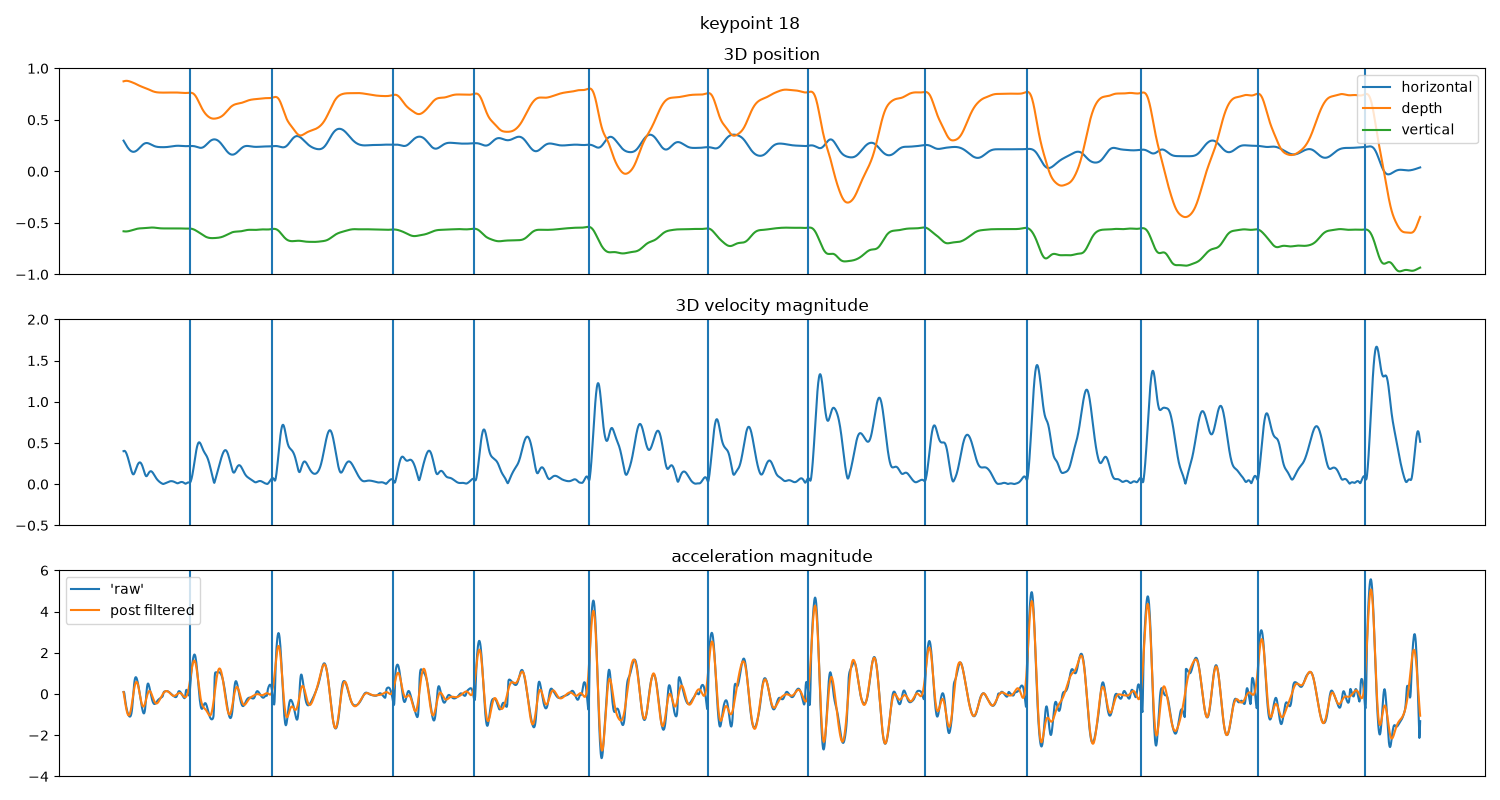

In [79]:
KPT_IDX = 18
cut = 250
delta_t = 1 / metadata["fps"]


position = keypoints[cut:, KPT_IDX, :]  # meters

velocity = np.gradient(position, delta_t, axis=0)  # vector, m/s
velocity_magnitude = np.linalg.norm(velocity, axis=1)  # vector magnitude

acceleration_magnitude = np.gradient(velocity_magnitude, delta_t, axis=0)  # vector, m/s^2


from scipy.signal import butter

nyquist = metadata["fps"] / 2
normal_cutoff = 2 / nyquist
b, a = butter(4, normal_cutoff, btype="low")
filtered_acc_mag = filtfilt(b,a,acceleration_magnitude)


plt.close("all")
fig, axs = plt.subplots(3, 1, figsize=(15, 8))
fig.suptitle(f"keypoint {KPT_IDX}")

axs[0].set_title("3D position")
axs[0].plot(position, label=["horizontal", "depth", "vertical"])
axs[0].legend()
axs[0].set_ylim([-1,1])

axs[1].set_title("3D velocity magnitude")
axs[1].plot(velocity_magnitude)
axs[1].set_ylim([-0.5,2])

axs[2].set_title("acceleration magnitude")
axs[2].plot(acceleration_magnitude, label="'raw'")
axs[2].plot(filtered_acc_mag, label='post filtered')
axs[2].legend()
# axs[2].hlines(baseline_mean, 0, len(acceleration_magnitude))
# axs[2].hlines(baseline_mean+baseline_std*3, 0, len(acceleration_magnitude))
axs[2].set_ylim([-4,6])


for ax in axs[:]:
    ax.set_xticks([])
    ax.vlines(170, -10,10)
    ax.vlines(380, -10,10)
    ax.vlines(690, -10,10)
    ax.vlines(895, -10,10)
    ax.vlines(1190, -10,10)
    ax.vlines(1495, -10,10)
    ax.vlines(1750, -10,10)
    ax.vlines(2050, -10,10)
    ax.vlines(2310, -10,10)
    ax.vlines(2600, -10,10)
    ax.vlines(2900, -10,10)
    ax.vlines(3175, -10,10)
plt.tight_layout()

In [44]:
baseline = acceleration_magnitude[50:150]
baseline_mean = np.nanmean(baseline)
baseline_std = np.nanstd(baseline)
print(baseline_mean, baseline_std)

-0.10526947278302896 0.3033764187640246
